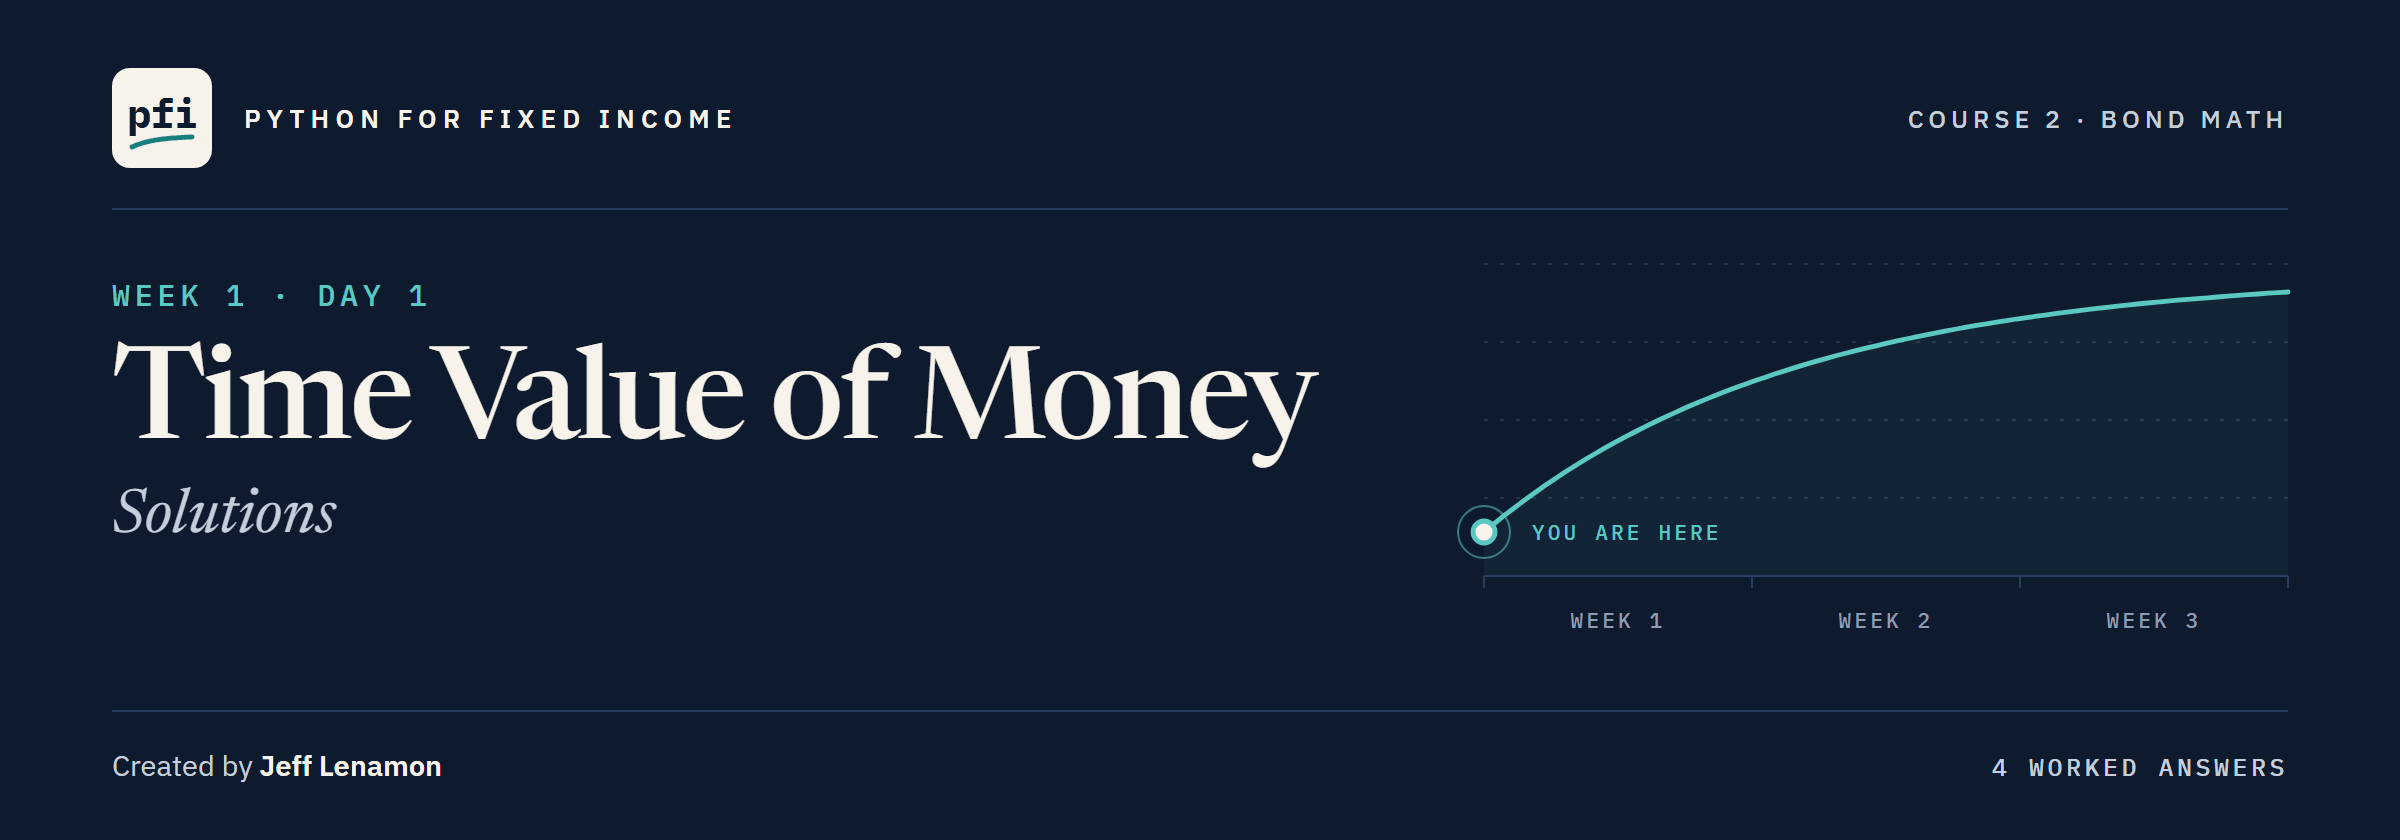

# Time Value of Money: Solutions

Week 1, Day 1. Worked answers to the exercises. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course02_bond_math/week1/day1/01_time_value_of_money_solutions.ipynb)

## Exercises

Run the next three cells first: the work folder with the module as the notebook ends, the imports and the bonds, and `check`.

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/course02_bond_math/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}start_of_day/start_day.py
from start_day import start_day

# a new work folder: the Excel files, and the module and its tests as notebook 01 ends.
# To start the day again, restart the kernel and run all cells.
work = start_day(1, after=1)

Work folder pfi_course2_01_k4w7q2xr: 2 data files, the module as notebook 01 left it, 1 commit


In [2]:
import importlib

import pandas as pd

import bondmath

tvm = pd.read_csv('bondmath_excel_reference_tvm.csv', index_col='case_id')
exercise_bonds = pd.DataFrame({
    'issuer': ['Ostrevale Telecom', 'Tarnwick Utilities', 'Osmere Chemicals', 'Calderby Retail'],
    'ticker': ['OSTV', 'TRNW', 'OSMC', 'CLDB'],
    'years': [4, 2, 6, 8],
    'yield_pct': [5.8, 4.3, 5.35, 8.6],
})

In [3]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

### Exercise 1

In [4]:
pairs = zip(exercise_bonds['yield_pct'], exercise_bonds['years'])
exercise_bonds['pv_of_100'] = [bondmath.present_value(100, y, t) for y, t in pairs]
ex1_osmere = exercise_bonds.loc[2, 'pv_of_100']
ex1_lowest = exercise_bonds.loc[exercise_bonds['pv_of_100'].idxmin(), 'ticker']
check('Exercise 1 Osmere', ex1_osmere, 72.84897770986194)
check('Exercise 1 lowest', ex1_lowest, 'CLDB')

Exercise 1 Osmere: correct
Exercise 1 lowest: correct


Calderby, 8 years at 8.60 percent, keeps least of its 100: 50.99.

### Exercise 2

In [5]:
# a dictionary of columns: the years first, then one column per ticker
ladder = {'years': [k / 2 for k in range(1, 11)]}
for ticker, y in zip(exercise_bonds['ticker'], exercise_bonds['yield_pct']):
    ladder[ticker] = [bondmath.present_value(1, y, t) for t in ladder['years']]
ex2_ladder = pd.DataFrame(ladder)
ex2_rows = len(ex2_ladder)
ex2_cldb_5y = ex2_ladder['CLDB'].iloc[-1]
check('Exercise 2 rows', ex2_rows, 10)
check('Exercise 2 Calderby at 5 years', ex2_cldb_5y, 0.6563823821846481)

Exercise 2 rows: correct
Exercise 2 Calderby at 5 years: correct


### Exercise 3

In [6]:
quarterly = bondmath.future_value(1_000_000, 4.3, 2, 4)
annual = bondmath.future_value(1_000_000, 4.3, 2, 1)
ex3_difference = quarterly - annual
check('Exercise 3 difference', ex3_difference, 1457.2615362685174)

Exercise 3 difference: correct


### Exercise 4

In [7]:
%%writefile -a bondmath.py


def discount_factor(rate_pct: float, years: float, frequency: int = 2) -> float:
    """The value today of 1 due in `years`, at an annual rate compounded `frequency` times a year.

    Units: rate_pct in percent, years in years. Between 0 and 1 for a positive rate.
    Convention: periodic compounding, 1 / (1 + rate / frequency) ** (frequency x years).
    Excel: =-PV(rate_pct/100/frequency, frequency*years, 0, 1)
    """
    # the present value of 1 is the discount factor
    return present_value(1.0, rate_pct, years, frequency)

Appending to bondmath.py


In [8]:
%%writefile -a test_bondmath.py


def test_discount_factor_matches_excel_pv():
    for row in tvm_rows("PV"):
        amount, rate_pct = float(row["amount"]), float(row["rate_pct"])
        years, frequency = float(row["years"]), int(row["frequency"])
        factor = bondmath.discount_factor(rate_pct, years, frequency)
        # Excel's PV of an amount is minus the amount times the discount factor
        assert factor * amount == pytest.approx(-float(row["excel_value"]), abs=1e-6), row["case_id"]

Appending to test_bondmath.py


In [9]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

....                                                                     [100%]
4 passed in 0.50s



In [10]:
importlib.reload(bondmath)
ex4_value = bondmath.discount_factor(5.35, 6)
check('Exercise 4 discount factor', ex4_value, 0.7284897770986194)

Exercise 4 discount factor: correct


### Exercise 5: AI check

The bug: `(1 + rate_pct / 100) ** years` compounds once a year, whatever `frequency` says.
The first row it fails, `tvm_pv_01`, is semiannual; the fix divides the rate by the frequency and multiplies the years by it.

In [11]:
def assistant_present_value(amount, rate_pct, years, frequency=2):
    """Discount an amount due in `years` at an annual rate compounded `frequency` times a year.

    Units: amount in dollars (or per 100 of face), rate_pct in percent, years in years.
    Convention: periodic compounding, amount / (1 + rate / frequency) ** (frequency x years).
    """
    if frequency not in (1, 2, 4):
        raise ValueError(f'frequency must be 1, 2, or 4, not {frequency}')
    # the fix: the rate per period, over frequency x years periods
    return amount / (1 + rate_pct / 100 / frequency) ** (frequency * years)

In [12]:
pv_rows = tvm[tvm['function'] == 'PV']
columns = zip(pv_rows.index, pv_rows['amount'], pv_rows['rate_pct'], pv_rows['years'],
              pv_rows['frequency'], pv_rows['excel_value'])
for case, amount, rate_pct, years, frequency, excel in columns:
    result = assistant_present_value(amount, rate_pct, years, frequency)
    # Excel's PV is negative, so the function should return minus Excel's value
    assert abs(result + excel) < 1e-6, f'{case}: {result:.6f} against {-excel:.6f}'
print(f'All {len(pv_rows)} PV rows match Excel')

All 18 PV rows match Excel


In [13]:
ex5_quorvane = assistant_present_value(100, 5.4, 5)
ex5_rows = len(pv_rows)
check('Exercise 5 Quorvane', ex5_quorvane, 76.61178196895271)
check('Exercise 5 rows checked', ex5_rows, 18)

Exercise 5 Quorvane: correct
Exercise 5 rows checked: correct


[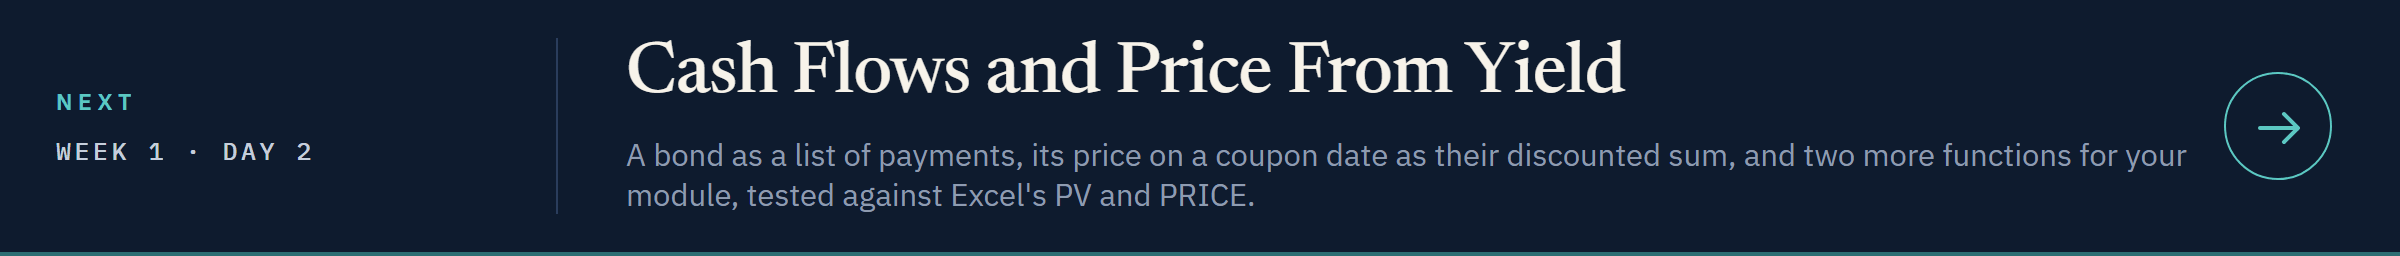](../day2/02_cash_flows_and_price_from_yield.ipynb)

[Open Day 2 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course02_bond_math/week1/day2/02_cash_flows_and_price_from_yield.ipynb)